# Deep Learning — Implementation Cheatsheet

Theory: [deep_learning.md](deep_learning.md) · Metrics: [evaluation_metrics.md](../01_toolkit/evaluation_metrics.md#6-deep-learning-training-curves)

Two parts, Keras (TensorFlow) in both:

| Part | Model | Data | Question |
|---|---|---|---|
| **A** | **ANN** (dense network) | ExtraaLearn leads (tabular, same as [classification](../04_classification/classification.ipynb)) | Does a neural net beat Random Forest on tabular data? |
| **B** | **CNN** (convolutional network) | Fashion-MNIST (28×28 clothing images, 10 classes) | How do CNNs compare to an ANN on images? |

## 0. Setup

In [1]:
import os, random, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # silence TensorFlow C++ logs
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"    # silence the oneDNN notice (and make CPU results deterministic)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (recall_score, precision_score, f1_score, roc_auc_score, accuracy_score,
                             ConfusionMatrixDisplay, classification_report)

def set_seed(seed=1):
    """Reproducibility: fix the seed in the 3 libraries."""
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)

def plot_history(history, metric, title):
    """Training vs validation curves: the #1 diagnostic in deep learning."""
    h = pd.DataFrame(history.history)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    h[["loss", "val_loss"]].plot(ax=ax[0], title=f"{title}: loss")
    h[[metric, f"val_{metric}"]].plot(ax=ax[1], title=f"{title}: {metric}")
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


---
# Part A: ANN on tabular data

## A1. Data (same cleaning as the classification notebook)

In [2]:
df = pd.read_csv("../data/extraalearn.csv").drop(columns="ID").drop_duplicates().reset_index(drop=True)
yes_no = ["print_media_type1", "print_media_type2", "digital_media", "educational_channels", "referral"]
df[yes_no] = (df[yes_no] == "Yes").astype(int)

X = pd.get_dummies(df.drop(columns="status"), drop_first=True, dtype=int)
y = df["status"].values

# Train / validation / test: validation is used by EarlyStopping, test is touched only once at the end
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=1)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.20, stratify=y_tmp, random_state=1)

# Neural nets NEED scaled inputs (gradient descent converges badly otherwise)
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

# Imbalance (30% positive): weight the minority class more, same idea as class_weight="balanced"
class_weight = {0: 1.0, 1: (y_train == 0).sum() / (y_train == 1).sum()}
print(X_train_s.shape, X_val_s.shape, X_test_s.shape, "| class_weight:", class_weight)

(2574, 16) (644, 16) (1380, 16) | class_weight: {0: 1.0, 1: np.float64(2.3472041612483747)}


## A2. Baseline ANN: no regularization
`Dense → Dense → sigmoid` output. **Binary** classification uses `binary_crossentropy` with a `sigmoid` output.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

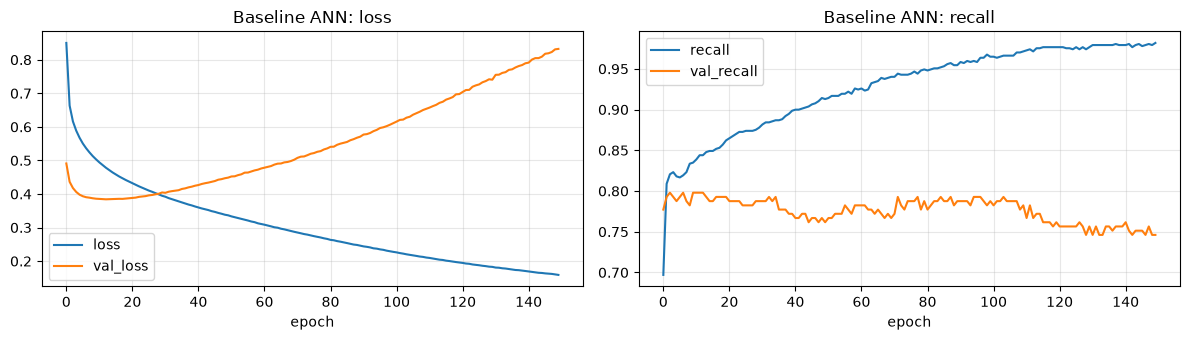

In [3]:
def build_ann(dropout=0.0, l2=0.0):
    model = keras.Sequential([
        keras.Input(shape=(X_train_s.shape[1],)),
        layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")])
    return model

set_seed()
ann_base = build_ann()
ann_base.summary()
hist_base = ann_base.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                         epochs=150, batch_size=32, class_weight=class_weight, verbose=0)
plot_history(hist_base, "recall", "Baseline ANN")

**Classic overfitting:** training loss keeps going down while **validation loss goes up** after a few epochs. The network is memorizing the training rows.

## A3. Regularized ANN: Dropout + L2 + EarlyStopping
- **Dropout**: randomly switches off neurons during training, so the network can't rely on any single one.
- **L2**: penalizes large weights (same idea as Ridge).
- **EarlyStopping**: stops when `val_loss` stops improving and **restores the best weights**.

stopped at epoch 68, best epoch 53


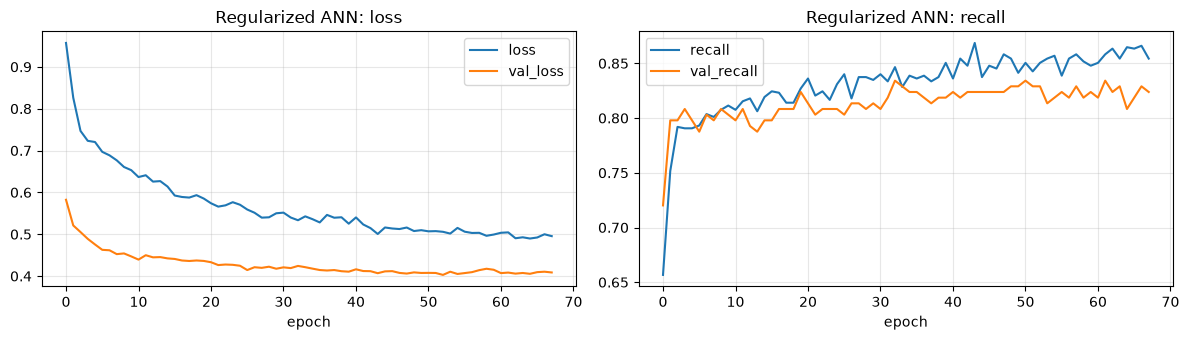

In [4]:
set_seed()
ann = build_ann(dropout=0.3, l2=1e-3)
early_stop = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
hist = ann.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
               epochs=300, batch_size=32, class_weight=class_weight, callbacks=[early_stop], verbose=0)
print(f"stopped at epoch {len(hist.history['loss'])}, best epoch {np.argmin(hist.history['val_loss']) + 1}")
plot_history(hist, "recall", "Regularized ANN")

## A4. Evaluate on test & compare with the classification notebook

In [5]:
def clf_scores(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"recall": recall_score(y_true, pred), "precision": precision_score(y_true, pred),
            "f1": f1_score(y_true, pred), "roc_auc": roc_auc_score(y_true, proba)}

ann_results = pd.DataFrame({
    "ANN baseline (150 epochs)": clf_scores(y_test, ann_base.predict(X_test_s, verbose=0).ravel()),
    "ANN regularized": clf_scores(y_test, ann.predict(X_test_s, verbose=0).ravel()),
    "Random Forest (from classification.ipynb)": {"recall": 0.877, "precision": 0.667, "f1": 0.757, "roc_auc": 0.928},
}).T.round(3)
ann_results

,recall,precision,f1,roc_auc
ANN baseline (150 epochs),0.743,0.630,0.682,0.872
ANN regularized,0.801,0.697,0.745,0.914
Random Forest (from classification.ipynb),0.877,0.667,0.757,0.928


**Takeaway:** on a small tabular dataset (~3k training rows) a regularized ANN gets close to Random Forest, but it **doesn't beat it** and it's harder to tune and explain. **Tree ensembles are still the default for tabular data**. Deep learning wins on **images, text and audio** (Part B).

---
# Part B: CNN on images

## B1. Data: Fashion-MNIST
70,000 grayscale 28×28 images, 10 clothing classes. Keras downloads it on first run (~30 MB, cached in `~/.keras`).

(20000, 28, 28) (10000, 28, 28)


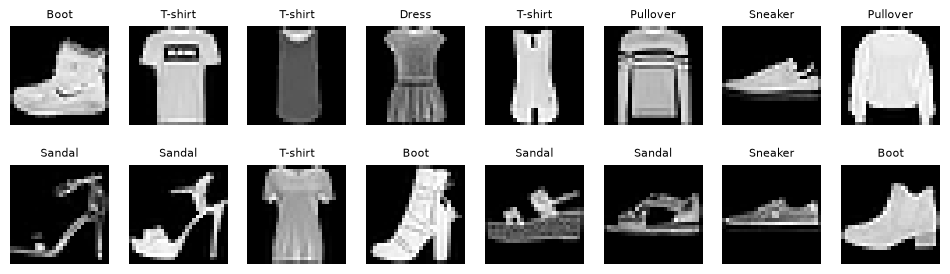

In [6]:
(Xi_train, yi_train), (Xi_test, yi_test) = keras.datasets.fashion_mnist.load_data()
class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]

# Use a subset so the notebook runs in a few minutes on a CPU
Xi_train, yi_train = Xi_train[:20000], yi_train[:20000]
print(Xi_train.shape, Xi_test.shape)

fig, ax = plt.subplots(2, 8, figsize=(12, 3.3))
for i, a in enumerate(ax.ravel()):
    a.imshow(Xi_train[i], cmap="gray"); a.set_title(class_names[yi_train[i]], fontsize=8); a.axis("off")
plt.show()

## B2. Preprocessing
- **Normalize** pixels 0–255 to 0–1 (same role as scaling).
- **Add the channel dimension**: CNNs expect `(height, width, channels)`, here 1 channel (grayscale; RGB = 3).
- Labels stay as integers and we use `sparse_categorical_crossentropy`. (With `to_categorical` one-hot labels you'd use `categorical_crossentropy`; same result.)

In [7]:
Xi_train_n = (Xi_train / 255.0)[..., np.newaxis].astype("float32")
Xi_test_n = (Xi_test / 255.0)[..., np.newaxis].astype("float32")
Xi_train_n.shape, Xi_train_n.min(), Xi_train_n.max()

((20000, 28, 28, 1), np.float32(0.0), np.float32(1.0))

## B3. Baseline: ANN on flattened pixels
`Flatten` turns 28×28 into 784 numbers and **throws away the spatial structure** (which pixels are neighbors).

In [8]:
set_seed()
ann_img = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax"),          # multiclass: softmax + 10 units
])
ann_img.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_ann_img = ann_img.fit(Xi_train_n, yi_train, validation_split=0.15, epochs=15, batch_size=128,
                           callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
                           verbose=0)
print(f"ANN params: {ann_img.count_params():,}")

ANN params: 101,770


## B4. CNN
Conv blocks **learn filters** (edges, then textures, then shapes). Pooling shrinks the image and keeps the strongest signals.

`[Conv → BatchNorm → MaxPool] × 2 → Flatten → Dense → Dropout → Softmax`

In [9]:
set_seed()
cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),                      # 28x28 -> 14x14
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),                      # 14x14 -> 7x7
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,026 (1.61 MB)

 Trainable params: 421,834 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

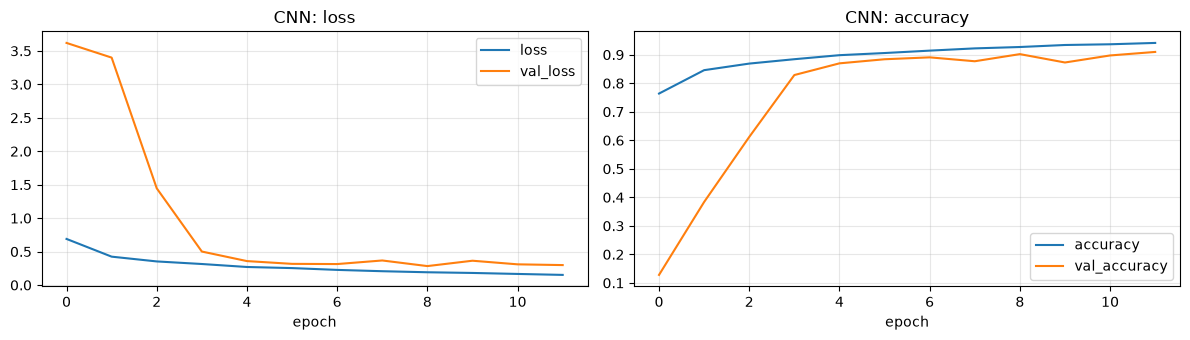

In [10]:
hist_cnn = cnn.fit(Xi_train_n, yi_train, validation_split=0.15, epochs=15, batch_size=128,
                   callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
                   verbose=0)
plot_history(hist_cnn, "accuracy", "CNN")

## B5. Evaluate & compare

In [11]:
img_results = pd.DataFrame({
    "ANN (flattened pixels)": {"test_accuracy": ann_img.evaluate(Xi_test_n, yi_test, verbose=0)[1],
                               "params": ann_img.count_params()},
    "CNN": {"test_accuracy": cnn.evaluate(Xi_test_n, yi_test, verbose=0)[1], "params": cnn.count_params()},
}).T
img_results["test_accuracy"] = img_results["test_accuracy"].round(3)
img_results["params"] = img_results["params"].astype(int)
img_results

,test_accuracy,params
ANN (flattened pixels),0.861,101770
CNN,0.896,422026


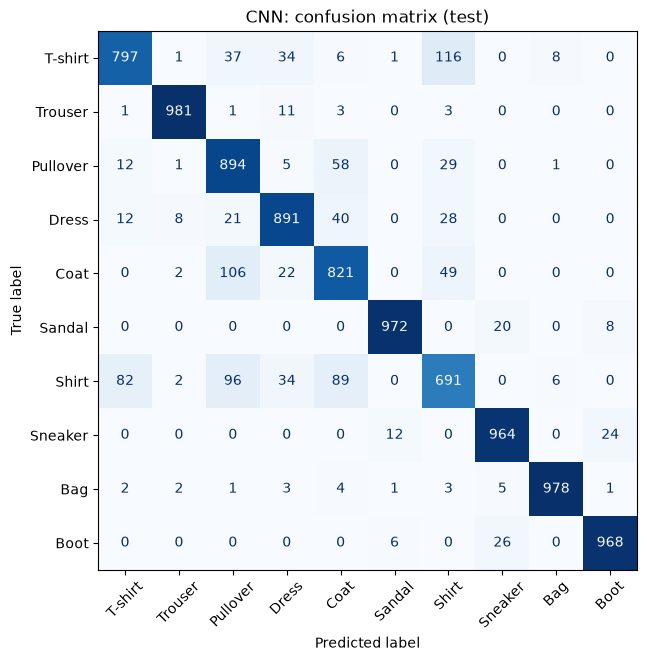

              precision    recall  f1-score   support

     T-shirt      0.880     0.797     0.836      1000
     Trouser      0.984     0.981     0.982      1000
    Pullover      0.773     0.894     0.829      1000
       Dress      0.891     0.891     0.891      1000
        Coat      0.804     0.821     0.812      1000
      Sandal      0.980     0.972     0.976      1000
       Shirt      0.752     0.691     0.720      1000
     Sneaker      0.950     0.964     0.957      1000
         Bag      0.985     0.978     0.981      1000
        Boot      0.967     0.968     0.968      1000

    accuracy                          0.896     10000
   macro avg      0.897     0.896     0.895     10000
weighted avg      0.897     0.896     0.895     10000



In [12]:
pred_cnn = cnn.predict(Xi_test_n, verbose=0).argmax(axis=1)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(yi_test, pred_cnn, display_labels=class_names, ax=ax,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("CNN: confusion matrix (test)"); plt.show()
print(classification_report(yi_test, pred_cnn, target_names=class_names, digits=3))

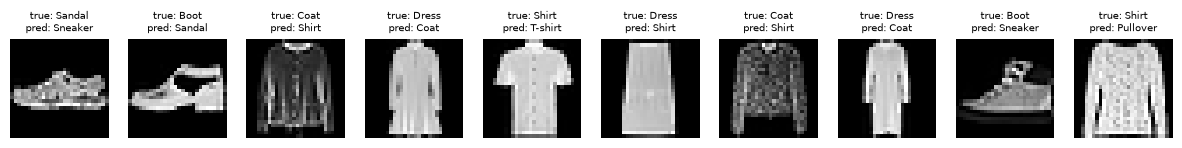

In [13]:
# Look at the mistakes: are they reasonable?
wrong = np.where(pred_cnn != yi_test)[0][:10]
fig, ax = plt.subplots(1, 10, figsize=(15, 2.2))
for a, i in zip(ax, wrong):
    a.imshow(Xi_test[i], cmap="gray"); a.axis("off")
    a.set_title(f"true: {class_names[yi_test[i]]}\npred: {class_names[pred_cnn[i]]}", fontsize=7)
plt.show()

## Conclusions
- **Tabular data:** regularization took the ANN from recall 0.74 / AUC 0.87 to **0.80 / 0.91**, still below Random Forest (**0.88 / 0.93**). Start with tree ensembles.
- **Images:** the CNN beats the flattened ANN (**~90% vs ~86%** test accuracy) because convolutions keep the **spatial structure**. Most of its parameters are in the `Dense` layer after `Flatten`; the conv layers themselves are tiny (shared 3×3 filters).
- **Always plot training vs validation curves.** The gap between them tells you whether you're overfitting.
- **Regularization toolbox:** Dropout, L2, BatchNorm, EarlyStopping, data augmentation (for images).
- Most errors are between **similar classes**: **Shirt** is the worst class (F1 ≈ 0.73), confused with T-shirt / Pullover / Coat, which humans also confuse.
- **Next level for real images** (like the Food Recognition project): **transfer learning**. Reuse a network pre-trained on ImageNet (VGG16, ResNet, EfficientNet), freeze it, and train only a new head. See [deep_learning.md](deep_learning.md#transfer-learning).